<a href="https://colab.research.google.com/github/iamashwinijoshi/online-retail-analysis/blob/main/Online_Retail_BigData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:

import zipfile
import os

# Extract the ZIP file
with zipfile.ZipFile("/content/online+retail.zip", "r") as zip_ref:
    zip_ref.extractall("/content/online_retail_data")

# Display the extracted files
os.listdir("/content/online_retail_data")


['Online Retail.xlsx']

In [5]:

import pandas as pd

# Load the Excel dataset
df = pd.read_excel("/content/online_retail_data/Online Retail.xlsx")

# Display the first five rows
df.head()


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [6]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the column names
print("\nColumn names:")
print(df.columns)

# Check the data types and non-missing values
print("\nDataset information:")
df.info()


Dataset shape: (541909, 8)

Column names:
Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [7]:

# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)


Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [8]:

# Count the number of completely duplicated rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 5268


In [14]:

# Display the first 10 duplicate rows
df[df.duplicated()].head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country


In [15]:

# Remove exact duplicate rows
df = df.drop_duplicates()

# Check the new dataset size
print("Dataset shape after removing duplicates:", df.shape)

# Verify that no exact duplicate rows remain
print("Remaining duplicate rows:", df.duplicated().sum())


Dataset shape after removing duplicates: (536641, 8)
Remaining duplicate rows: 0


In [16]:

# Count missing values after removing duplicates
missing_values = df.isnull().sum()

print("Missing values after duplicate removal:")
print(missing_values)


Missing values after duplicate removal:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [17]:

# Identify cancelled invoices
cancelled_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Count rows associated with cancelled invoices
print("Cancelled transaction rows:", cancelled_mask.sum())

# Display a few examples
df.loc[cancelled_mask].head()


Cancelled transaction rows: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


In [18]:

# Create a separate dataset without cancelled invoices
sales_df = df[
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Compare the dataset sizes
print("Rows before excluding cancellations:", len(df))
print("Rows after excluding cancellations:", len(sales_df))

# Verify that no cancelled invoice numbers remain
print(
    "Cancelled rows remaining:",
    sales_df["InvoiceNo"].astype(str).str.startswith("C").sum()
)


Rows before excluding cancellations: 536641
Rows after excluding cancellations: 527390
Cancelled rows remaining: 0


In [19]:

# Count records with zero or negative quantities
print("Zero quantity rows:", (sales_df["Quantity"] == 0).sum())
print("Negative quantity rows:", (sales_df["Quantity"] < 0).sum())

# Count records with zero or negative unit prices
print("Zero unit price rows:", (sales_df["UnitPrice"] == 0).sum())
print("Negative unit price rows:", (sales_df["UnitPrice"] < 0).sum())



Zero quantity rows: 0
Negative quantity rows: 1336
Zero unit price rows: 2510
Negative unit price rows: 2


In [21]:

# Create the final cleaned dataset
cleaned_df = sales_df.dropna(subset=["Description"]).copy()

# Check the cleaned dataset
print("Final cleaned dataset shape:", cleaned_df.shape)
print("Missing descriptions:", cleaned_df["Description"].isnull().sum())
print("Remaining duplicate rows:", cleaned_df.duplicated().sum())
print(
    "Cancelled rows remaining:",
    cleaned_df["InvoiceNo"].astype(str).str.startswith("C").sum()
)


Final cleaned dataset shape: (525936, 8)
Missing descriptions: 0
Remaining duplicate rows: 0
Cancelled rows remaining: 0


In [23]:

# Create a revenue column
cleaned_df["Revenue"] = (
    cleaned_df["Quantity"] * cleaned_df["UnitPrice"]
)

# Display the first five rows
cleaned_df[["Quantity", "UnitPrice", "Revenue"]].head()


,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


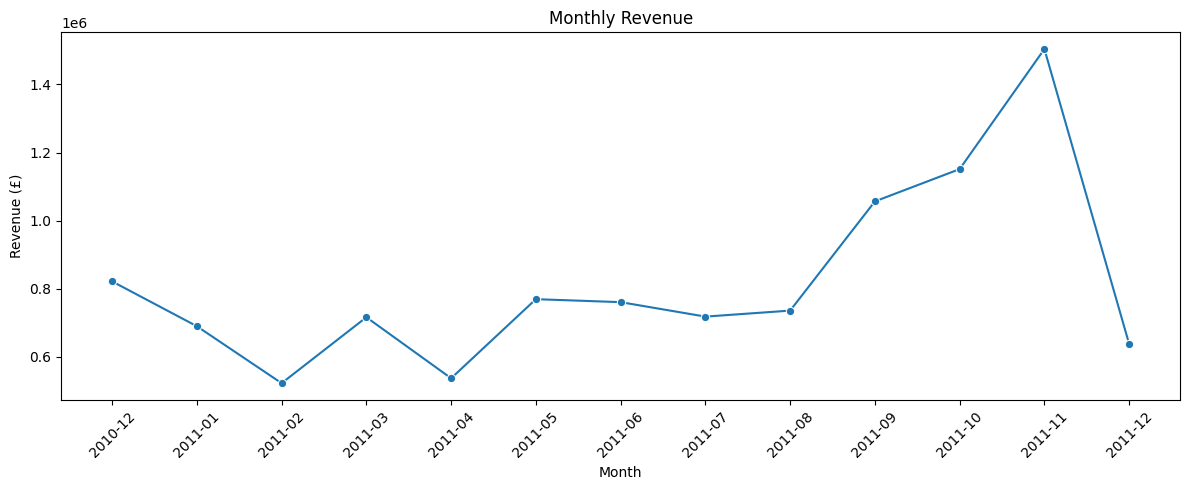

In [24]:

# Calculate monthly revenue
monthly_revenue = (
    cleaned_df.groupby(
        cleaned_df["InvoiceDate"].dt.to_period("M")
    )["Revenue"].sum()
)

# Plot monthly revenue
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=monthly_revenue.index.astype(str),
    y=monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


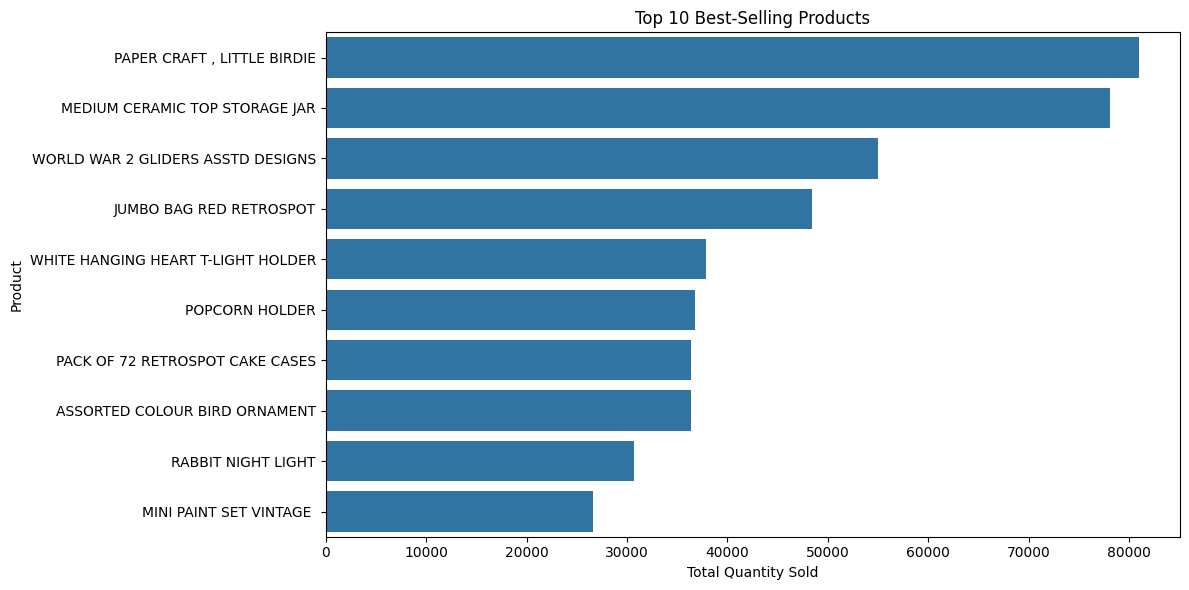

In [25]:
# Find the 10 best-selling products by quantity
top_products = (
    cleaned_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Display the results as a graph
plt.figure(figsize=(12, 6))
sns.barplot(x=top_products.values, y=top_products.index)

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

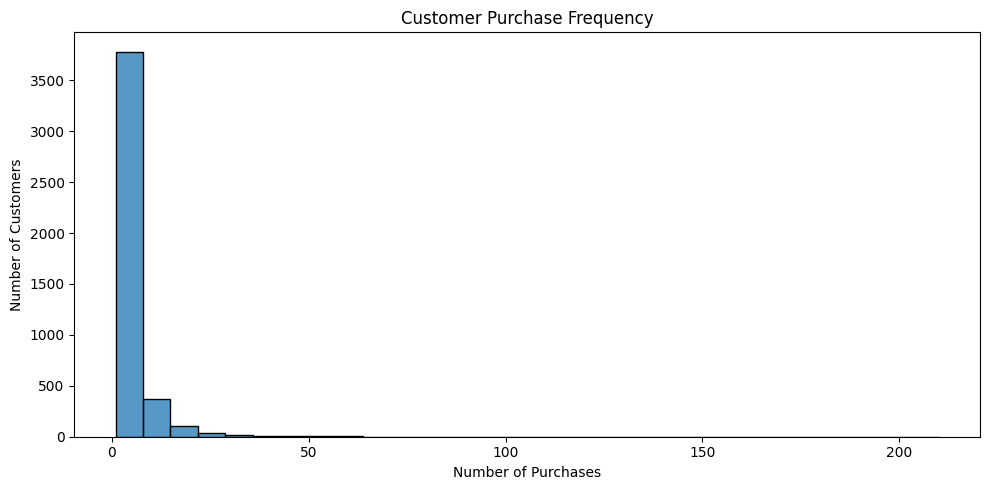

In [26]:
# Count the number of purchases made by each customer
purchase_frequency = cleaned_df.groupby("CustomerID")["InvoiceNo"].nunique()

# Display the distribution of purchase frequency
plt.figure(figsize=(10, 5))
sns.histplot(purchase_frequency, bins=30)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

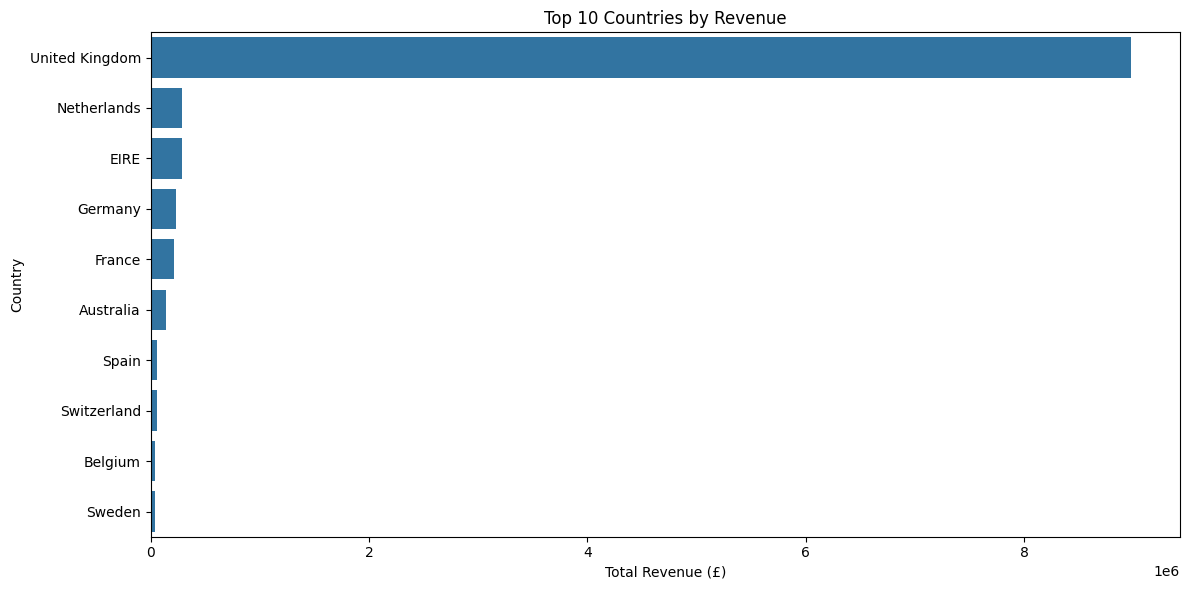

In [27]:
# Calculate total revenue for each country
country_revenue = (
    cleaned_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Plot the top 10 countries by revenue
plt.figure(figsize=(12, 6))
sns.barplot(x=country_revenue.values, y=country_revenue.index)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [28]:
import pandas as pd

# Reference date for calculating how recently customers purchased
reference_date = cleaned_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for each customer
rfm = cleaned_df.dropna(subset=["CustomerID"]).groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [30]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Scale the RFM values so they can be compared fairly
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

# Divide customers into 4 groups
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

# Display the RFM data with customer group numbers
rfm.head()

# Summarize the characteristics of each customer cluster
cluster_summary = rfm.groupby("Cluster").agg(
    Number_of_Customers=("Recency", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean")
).round(2)

cluster_summary

,Number_of_Customers,Average_Recency,Average_Frequency,Average_Monetary
Cluster,,,,
0,3053,43.91,3.66,1344.28
1,211,15.67,22.05,12435.09
2,1062,248.56,1.55,476.33
3,13,7.38,82.69,127187.96


In [31]:
# Prepare customer purchase dates
customer_data = cleaned_df.dropna(subset=["CustomerID"]).copy()

# Get each customer's last purchase date
last_purchase = customer_data.groupby("CustomerID")["InvoiceDate"].max()

# Set the prediction reference date
reference_date = cleaned_df["InvoiceDate"].max().normalize()

# Create a table of customer last-purchase dates
customer_ml = pd.DataFrame({
    "LastPurchaseDate": last_purchase
})

customer_ml.head()

,LastPurchaseDate
CustomerID,
12346.0,2011-01-18 10:01:00
12347.0,2011-12-07 15:52:00
12348.0,2011-09-25 13:13:00
12349.0,2011-11-21 09:51:00
12350.0,2011-02-02 16:01:00


In [32]:
# Count purchases and calculate spending for each customer
customer_features = customer_data.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    AverageOrderValue=("Revenue", "mean")
)

# Calculate days since the last purchase
customer_features["Recency"] = (
    reference_date - last_purchase.dt.normalize()
).dt.days

customer_features.head()

,Frequency,Monetary,AverageOrderValue,Recency
CustomerID,,,,
12346.0,1,77183.60,77183.600000,325
12347.0,7,4310.00,23.681319,2
12348.0,4,1797.24,57.975484,75
12349.0,1,1757.55,24.076027,18
12350.0,1,334.40,19.670588,310


In [33]:
# Sort all transactions by date
transactions = customer_data.sort_values("InvoiceDate").copy()

# Choose a historical cutoff date
cutoff_date = transactions["InvoiceDate"].max() - pd.Timedelta(days=30)

# Use purchases before the cutoff to build customer features
past_data = transactions[transactions["InvoiceDate"] <= cutoff_date]

# Check the date range
print("Historical cutoff date:", cutoff_date)
print("Last date in feature data:", past_data["InvoiceDate"].max())
print("Total historical transactions:", len(past_data))

Historical cutoff date: 2011-11-09 12:50:00
Last date in feature data: 2011-11-09 12:49:00
Total historical transactions: 328464


In [34]:
# Transactions in the 30-day prediction window
future_data = transactions[
    (transactions["InvoiceDate"] > cutoff_date) &
    (transactions["InvoiceDate"] <= cutoff_date + pd.Timedelta(days=30))
]

# Label customers: 1 = purchased again, 0 = did not
future_purchases = future_data.groupby("CustomerID")["InvoiceNo"].nunique()

customer_features["PurchasedNext30Days"] = (
    customer_features.index.isin(future_purchases.index)
).astype(int)

print(customer_features["PurchasedNext30Days"].value_counts())

PurchasedNext30Days
0    2690
1    1649
Name: count, dtype: int64


In [35]:
# Build customer features using historical data only
past_data = past_data.dropna(subset=["CustomerID"]).copy()
past_data["Revenue"] = past_data["Quantity"] * past_data["UnitPrice"]

past_features = past_data.groupby("CustomerID").agg(
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    AverageOrderValue=("Revenue", "mean"),
    LastPurchase=("InvoiceDate", "max")
)

past_features["Recency"] = (
    cutoff_date - past_features["LastPurchase"]
).dt.days

# Attach the target labels created earlier
past_features["PurchasedNext30Days"] = (
    past_features.index.isin(future_purchases.index)
).astype(int)

print("Customer records for modelling:", len(past_features))
print(past_features.head())

Customer records for modelling: 4070
            Frequency  Monetary  AverageOrderValue        LastPurchase  \
CustomerID                                                               
12346.0             1  77183.60       77183.600000 2011-01-18 10:01:00   
12347.0             6   4085.18          23.889942 2011-10-31 12:25:00   
12348.0             4   1797.24          57.975484 2011-09-25 13:13:00   
12350.0             1    334.40          19.670588 2011-02-02 16:01:00   
12352.0             8   2506.04          29.482824 2011-11-03 14:37:00   

            Recency  PurchasedNext30Days  
CustomerID                                
12346.0         295                    0  
12347.0           9                    1  
12348.0          44                    0  
12350.0         279                    0  
12352.0           5                    0  


In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Select features and target
X = past_features[
    ["Recency", "Frequency", "Monetary", "AverageOrderValue"]
]
y = past_features["PurchasedNext30Days"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
lr_predictions = lr_model.predict(X_test_scaled)

# Train Random Forest
rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced"
)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

# Compare model accuracy
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_predictions), 3))

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_predictions), 3))

print("\nLogistic Regression Report:")
print(classification_report(y_test, lr_predictions))

print("\nRandom Forest Report:")
print(classification_report(y_test, rf_predictions))

Logistic Regression Accuracy: 0.729
Random Forest Accuracy: 0.709

Logistic Regression Report:
              precision    recall  f1-score   support

           0       0.74      0.92      0.82       538
           1       0.69      0.36      0.47       276

    accuracy                           0.73       814
   macro avg       0.71      0.64      0.64       814
weighted avg       0.72      0.73      0.70       814


Random Forest Report:
              precision    recall  f1-score   support

           0       0.74      0.86      0.80       538
           1       0.60      0.41      0.49       276

    accuracy                           0.71       814
   macro avg       0.67      0.64      0.64       814
weighted avg       0.69      0.71      0.69       814



In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Prepare transactions
data = cleaned_df.dropna(subset=["CustomerID"]).copy()
data["Revenue"] = data["Quantity"] * data["UnitPrice"]
data = data.sort_values("InvoiceDate")

last_date = data["InvoiceDate"].max()
train_cutoff = last_date - pd.Timedelta(days=60)
test_cutoff = last_date - pd.Timedelta(days=30)

feature_cols = ["Recency", "Frequency", "Monetary", "AverageOrderValue"]

# Create historical customer features and future-purchase labels
def make_dataset(cutoff):
    history = data[data["InvoiceDate"] <= cutoff]
    future = data[
        (data["InvoiceDate"] > cutoff) &
        (data["InvoiceDate"] <= cutoff + pd.Timedelta(days=30))
    ]

    features = history.groupby("CustomerID").agg(
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum"),
        AverageOrderValue=("Revenue", "mean"),
        LastPurchase=("InvoiceDate", "max")
    )

    features["Recency"] = (
        cutoff - features["LastPurchase"]
    ).dt.days

    future_customers = future["CustomerID"].unique()
    features["Target"] = features.index.isin(future_customers).astype(int)

    return features[feature_cols], features["Target"]

# Earlier period for training; later period for testing
X_train, y_train = make_dataset(train_cutoff)
X_test, y_test = make_dataset(test_cutoff)

# Scale features for Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train both models
lr_model = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(
    n_estimators=100, random_state=42, class_weight="balanced"
)
rf_model.fit(X_train, y_train)

# Evaluate on the later period
lr_pred = lr_model.predict(X_test_scaled)
rf_pred = rf_model.predict(X_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred), 3))
print(classification_report(y_test, lr_pred, zero_division=0))

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred), 3))
print(classification_report(y_test, rf_pred, zero_division=0))

Logistic Regression Accuracy: 0.705
              precision    recall  f1-score   support

           0       0.78      0.77      0.77      2690
           1       0.56      0.59      0.58      1380

    accuracy                           0.71      4070
   macro avg       0.67      0.68      0.67      4070
weighted avg       0.71      0.71      0.71      4070

Random Forest Accuracy: 0.713
              precision    recall  f1-score   support

           0       0.72      0.93      0.81      2690
           1       0.68      0.29      0.41      1380

    accuracy                           0.71      4070
   macro avg       0.70      0.61      0.61      4070
weighted avg       0.71      0.71      0.67      4070

